# **Introduction to FlyWire — Part 3: From connectome to circuit**

How does the taste of sugar reach the muscles that make a fly eat?

When a fly's mouthparts touch sugar, it extends its proboscis to start feeding, a reflex called the proboscis extension response. In 2024, **Shiu et al.** (*Nature* 634, 210–219) used FlyWire to build a computational model of the entire fly brain and looked at which neurons responded to sugar stimulation. Among the responders was **MN9**, a motor neuron that drives proboscis extension. The model predicted sugar → feeding from the wiring alone, and several predictions were confirmed experimentally. In this notebook we do the connectome half of that study ourselves. 

And so, we need to:
* **extract** the subcircuit linking the sugar GRNs to MN9,
* build its **adjacency matrix** and give each connection a **sign** from neurotransmitter predictions,
* compute simple **graph statistics** to describe the circuit.

This notebook will be more interactive, with more gaps that need to be filled in. As always, the solution is provided in a dropdown.

## 0. Setup
As in Parts 1 and 2, [click here](colab.research.google.com/github/ryanrahy/fcnc_workshop/blob/master/day_1/FW_intro_part2_connections.ipynb) to run this notebook on Colab and run the following cell if running on a fresh machine or Colab.

In [ ]:
# run this cell if on a fresh machine or on Colab

# get code + data
!git clone https://github.com/ryanrahy/fcnc_workshop.git
import os
os.chdir('./fcnc_workshop/day1/')

# install missing packages
!pip install navis flybrains ipywidgets plotly pyarrow
!pip install fafbseg   # only needed for online mode (see below)

Next, choose **offline mode** (pre-downloaded data, no token) or **online mode** (live queries, needs `fafbseg` and a FlyWire token). We also use [`networkx`](https://networkx.org), the standard Python package for graphs (it is installed together with `navis`).

In [2]:
OFFLINE = True   # set to False to query FlyWire live

if OFFLINE:
    import fw_offline as flywire
else:
    from fafbseg import flywire

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

flywire.set_default_dataset("public")
NC = flywire.NeuronCriteria

Default dataset set to "public" (offline copy of materialization 783).


Let's load the annotations once, plus a small table that ships with this notebook: the names Shiu et al. used for neurons in the *subesophageal zone* (SEZ, the taste and feeding center of the fly brain). Many SEZ neurons have memorable names like *Roundup* or *G2N-1*. In FlyWire they mostly carry numbered types (`CB0553`, …). We translated the IDs from the authors' repository to v783.

In [8]:
# get all annotations; create a lookup table
ann = flywire.search_annotations(None)
# Use each neuron's cell type, or its hemibrain type if it has no cell type
ann["label"] = ann.cell_type.fillna(ann.hemibrain_type)
# One row per neuron, looked up by root ID (e.g. info.loc[root_id])
info = ann.drop_duplicates("root_id").set_index("root_id")
info

,supervoxel_id,pos_x,pos_y,pos_z,soma_x,soma_y,soma_z,nucleus_id,flow,super_class,...,side,nerve,vfb_id,fbbt_id,status,dimorphism,matching_notes,fru_dsx,synonyms,label
root_id,,,,,,,,,,,,,,,,,,,,,
720575940628857210,78112261444987077,109306.0,50491.0,3960.0,104904.0,47464.0,5461.0,2453924.0,intrinsic,central,...,left,NaN,fw138205,FBbt_20001935,NaN,isomorphic,NaN,NaN,NaN,PS180
720575940626838909,82475466912542440,172029.0,55635.0,1592.0,177472.0,56936.0,1429.0,7393349.0,intrinsic,central,...,right,NaN,fw000001,NaN,NaN,isomorphic,NaN,NaN,NaN,CB0924
720575940626046919,83038623024880664,180632.0,58664.0,1925.0,180632.0,58664.0,1925.0,7415038.0,intrinsic,central,...,right,NaN,fw000002,FBbt_20000538,NaN,isomorphic,NaN,NaN,NaN,AVLP429
720575940630311383,79801523353604463,133800.0,56063.0,1847.0,180728.0,61008.0,1630.0,7415013.0,intrinsic,central,...,right,NaN,fw000003,FBbt_20000260,NaN,isomorphic,NaN,NaN,NaN,AVLP151
720575940633370649,83038554439606237,180496.0,57448.0,2989.0,180496.0,57448.0,2989.0,7415848.0,intrinsic,visual_projection,...,right,NaN,fw000004,FBbt_00051248,NaN,isomorphic,NaN,NaN,NaN,LC27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
720575940650339961,81702991543049294,161088.0,79280.0,3677.0,161088.0,79280.0,3677.0,6918344.0,intrinsic,optic,...,right,NaN,fw010095,NaN,outlier_bio,isomorphic,NaN,NaN,NaN,Li02
720575940619997854,75720205111813659,74280.0,57640.0,3166.0,74280.0,57640.0,3166.0,1511338.0,intrinsic,optic,...,left,NaN,fw046509,NaN,NaN,isomorphic,NaN,NaN,NaN,MTe51
720575940632527683,82898435359563570,179084.0,67151.0,2520.0,210200.0,67728.0,3621.0,8516311.0,intrinsic,optic,...,right,NaN,fw050366,NaN,NaN,isomorphic,NaN,NaN,NaN,aMe6c


In [10]:
# A few neurons have two names in the original table, e.g. "nori/oink"
shiu_names = pd.read_csv("shiu_sez_names_783.csv").groupby("root_id")["name"].agg("/".join)

def nice_name(rid):
    # Shiu et al. name if there is one, else the FlyWire cell type
    label = info.label.get(rid, "?")
    if rid in shiu_names.index:
        return f"{shiu_names[rid]} ({label})"
    return str(label)

nice_name(720575940623211725)

'roundup (CB0553)'

---
## 1. The cast

### 1.1 The input: sugar-sensing neurons
These are the 21 sugar GRNs that Shiu et al. stimulated, copied from their code repository ([github.com/philshiu/Drosophila_brain_model](https://github.com/philshiu/Drosophila_brain_model)). Like most of the paper's analyses, these IDs are from materialization **630**. You know from Part 1 what that means - how do we get the root IDs belonging to materialization **783**? Fill in the gap in the code below!

<details><summary>Show solution</summary>

```python
upd = flywire.update_ids(all_630_ids)
# can also directly query changed IDs
upd[upd.changed]
```
</details>

In [ ]:
SUGAR_630 = [
    720575940624963786, 720575940630233916, 720575940637568838, 720575940638202345, 720575940617000768,
    720575940630797113, 720575940632889389, 720575940621754367, 720575940621502051, 720575940640649691,
    720575940639332736, 720575940616885538, 720575940639198653, 720575940620900446, 720575940617937543,
    720575940632425919, 720575940633143833, 720575940612670570, 720575940628853239, 720575940629176663,
    720575940611875570,
]
MN9_630 = [720575940660219265, 720575940645521262]

# Bring all IDs to v783
all_630_ids = SUGAR_630 + MN9_630
upd = ___
upd

,old_id,new_id,confidence,changed
0,720575940624963786,720575940624963786,1,False
1,720575940630233916,720575940630233916,1,False
2,720575940637568838,720575940637568838,1,False
3,720575940638202345,720575940638202345,1,False
4,720575940617000768,720575940617000768,1,False
5,720575940630797113,720575940630797113,1,False
6,720575940632889389,720575940632889389,1,False
7,720575940621754367,720575940621754367,1,False
8,720575940621502051,720575940621502051,1,False
9,720575940640649691,720575940640649691,1,False


In [18]:
# map the old IDs to the new ones
new_id = dict(zip(upd.old_id, upd.new_id))

# get the updated IDs for each group of neurons
sugar = [new_id[i] for i in SUGAR_630]
mn9 = [new_id[i] for i in MN9_630]

print(f"{len(sugar)} sugar GRNs, {len(mn9)} MN9 neurons (v783)")

21 sugar GRNs, 2 MN9 neurons (v783)


What does FlyWire's annotation table say about these 21 neurons?

In [19]:
# Count the sugar GRNs per combination of side, class and sub class
info.loc[sugar].value_counts(["side", "cell_class", "cell_sub_class"])

side  cell_class  cell_sub_class       
left  gustatory   sugar                    10
                  high_salt/heavy_metal     5
                  putative_attractive       4
                  sugar/low_salt            2
Name: count, dtype: int64

### 1.2 The output: MN9

In [20]:
# Rows: the two MN9 neurons; columns: a few annotation fields
info.loc[mn9, ["side", "super_class", "cell_class", "cell_sub_class", "cell_type", "top_nt", "top_nt_conf"]]

,side,super_class,cell_class,cell_sub_class,cell_type,top_nt,top_nt_conf
root_id,,,,,,,
720575940660219265,right,motor,brain_motor_neuron,ingestion_motor_neuron,CB0701,acetylcholine,0.439077
720575940618238523,left,motor,brain_motor_neuron,ingestion_motor_neuron,CB0701,acetylcholine,0.469764


In FlyWire, MN9 is a cell type named `CB0701`, an **ingestion motor neuron**, with one on each side. Its neurotransmitter is predicted to be acetylcholine, but insect motor neurons are glutamatergic. Yet another reminder that the predictions can be wrong. Here it doesn't matter, because MN9's outputs (onto muscles) lie outside the brain.

---
## 2. The feed-forward paths

A typical neuron has hundreds of partners, so the full set of neurons "connected to" the sugar GRNs quickly becomes the whole brain. We need a principled definition of the circuit. Here's ours:

> A neuron belongs to the subcircuit if it lies on a **short path** (at most `MAX_HOPS` connections) from any sugar GRN to any MN9.

For every neuron `n` we compute two numbers:

* `d_in[n]`: the number of hops from the nearest sugar GRN *to* `n`,
* `d_out[n]`: the number of hops from `n` to the nearest MN9.

`n` lies on such a path exactly when `d_in[n] + d_out[n] <= MAX_HOPS`.

```
 sugar GRN ──▶ A ──▶ B ──▶ MN9        d_in:  A=1, B=2
                                      d_out: A=2, B=1   →  A and B are on a 3-hop path
```

We'll only count connections with at least `THRESHOLD` synapses (see Part 2 on why).

We'll build this circuit in two steps:

* **Section 2, the feed-forward paths:** by hand, we find every path of at most `MAX_HOPS` connections from a sugar GRN to MN9. We take one step from each end (2.1), connect the two ends (2.2), collect everyone on a path (2.3) and put the path connections together (2.4).
* **Section 3, the complete circuit:** we then fetch *all* connections between the neurons on these paths, including the ones that don't lie on any path, see what they add, and automate both steps for any number of hops.

### 2.1 One step from each end

Let's start with the neurons **directly downstream** of the sugar GRNs. You've seen everything you need in Part 2 (Section 2.1):

1. Fetch the connections of the sugar GRNs (`sugar`). We only want their **outputs**, so switch off the other direction.
2. Keep only the connections with at least `THRESHOLD` synapses.

The last step, removing the sugar GRNs themselves from the list of partners, is given (GRNs also synapse onto each other!).

**Check:** you should find **90** neurons.

<details><summary>Show solution</summary>

```python
down1 = flywire.get_connectivity(sugar, upstream=False)
down1 = down1[down1.weight >= THRESHOLD]
```
</details>

In [ ]:
THRESHOLD = 5   # minimum number of synapses for a connection
MAX_HOPS = 3    # maximum path length from GRN to MN9

# 1. Get the connections of the sugar GRNs (outputs only)
down1 = ___

# 2. Keep only connections with at least THRESHOLD synapses
down1 = ___

# Given: the downstream partners, minus the sugar GRNs themselves
layer1 = np.setdiff1d(down1.post.unique(), sugar)
print(len(layer1), "neurons get >=", THRESHOLD, "synapses from the sugar GRNs")

90 neurons get >= 5 synapses from the sugar GRNs


Now the other end: the neurons **directly upstream** of MN9 (`mn9`). It's the same idea in the other direction. Think about which column of the connectivity table holds MN9's *partners* now: `pre` or `post`?

**Check:** **148** neurons upstream of MN9, and **3** neurons in both sets.

<details><summary>Show solution</summary>

```python
up1 = flywire.get_connectivity(mn9, downstream=False)
up1 = up1[up1.weight >= THRESHOLD]
pre_mn9 = np.setdiff1d(up1.pre.unique(), mn9)
```
</details>

In [ ]:
# 3. Get the connections of MN9 (inputs only), then filter by THRESHOLD
up1 = ___
up1 = ___

# 4. Which column holds MN9's partners: `pre` or `post`?
pre_mn9 = np.setdiff1d(up1.___.unique(), mn9)
print(len(pre_mn9), "neurons give >=", THRESHOLD, "synapses to MN9")

print("Neurons in both sets (= 2-hop paths GRN → X → MN9):", len(np.intersect1d(layer1, pre_mn9)))

148 neurons give >= 5 synapses to MN9
Neurons in both sets (= 2-hop paths GRN → X → MN9): 3


What kinds of neurons are the sugar GRNs talking to?

In [23]:
# The name of every layer1 neuron, then the 10 most common names
pd.Series([nice_name(n) for n in layer1]).value_counts().head(10)

?                  14
LB3b                6
CB0964              2
rattle (CB0499)     2
CB0573              2
CB0604              2
DNg103              2
CB0248              2
LB3d                2
CB0070              2
Name: count, dtype: int64

### 2.2 Connecting the two ends

We now have the neurons one step after the sugar GRNs (`layer1`) and one step before MN9 (`pre_mn9`). Paths from the GRNs to MN9 come in two kinds:

* **2 hops** (`GRN → X → MN9`): `X` is in *both* sets. You counted those above.
* **3 hops** (`GRN → a → b → MN9`): `a` is in `layer1`, `b` is in `pre_mn9`, and `a` connects to `b`.

For the 3-hop paths we need the "bridge" connections from `layer1` to `pre_mn9`:

1. Fetch the outputs of the `layer1` neurons and keep the connections with at least `THRESHOLD` synapses (just like `down1`).
2. Keep only the rows whose postsynaptic neuron is in `pre_mn9`. Hint: `.isin()`.

**Check:** **269** connections, from **49** `layer1` neurons to **80** `pre_mn9` neurons.

<details><summary>Show solution</summary>

```python
bridge = flywire.get_connectivity(layer1, upstream=False)
bridge = bridge[bridge.weight >= THRESHOLD]
bridge = bridge[bridge.post.isin(pre_mn9)]
```
</details>

In [ ]:
# 5. Get the outputs of the layer1 neurons
bridge = ___

# 6. Keep only connections with at least THRESHOLD synapses
bridge = ___

# 7. Keep only connections that end on a neuron in pre_mn9
bridge = ___

print(f"{len(bridge)} connections from {bridge.pre.nunique()} layer1 neurons "
      f"to {bridge.post.nunique()} pre_mn9 neurons")

269 connections from 49 layer1 neurons to 80 pre_mn9 neurons


In [25]:
bridge

,pre,post,weight
0,720575940628802069,720575940640589171,294
2,720575940628802069,720575940631959097,252
11,720575940610584945,720575940644653348,186
18,720575940610584945,720575940613347299,155
29,720575940625705930,720575940620156209,136
...,...,...,...
3903,720575940614763666,720575940627099338,5
3909,720575940632648868,720575940617787963,5
3913,720575940614998166,720575940615023535,5
3918,720575940619973712,720575940617787963,5


### 2.3 Who is in the circuit?

`layer1` and `pre_mn9` are only *candidates*: not every neuron downstream of the GRNs leads on to MN9, and not every input to MN9 receives anything from the GRNs. We keep only the neurons that lie on a path. There are two kinds of paths:

```
2 hops:   GRN ──▶ X ──────▶ MN9       X is in both layer1 and pre_mn9
3 hops:   GRN ──▶ a ──▶ b ──▶ MN9     a → b is a bridge connection (from 2.2)
```

We'll collect the neurons on each kind of path separately, and then combine them.

#### 2-hop paths: GRN → X → MN9

A neuron `X` on a 2-hop path receives input from a GRN *and* sends output to MN9, so it is in both `layer1` and `pre_mn9`. Hint: `np.intersect1d(x, y)` keeps the IDs that are in both `x` and `y`.

**Check:** **3** neurons.

<details><summary>Show solution</summary>

```python
two_hop = np.intersect1d(layer1, pre_mn9)
```
</details>

In [ ]:
# 8. Neurons on 2-hop paths: in both layer1 and pre_mn9
two_hop = np.intersect1d(___, ___)
two_hop

There are 3 neurons that are part of 2-hop paths.

#### 3-hop paths: GRN → a → b → MN9

Every bridge connection `a → b` is part of a 3-hop path: `a` receives input from a GRN (it's in `layer1`) and `b` sends output to MN9 (it's in `pre_mn9`). So the neurons on 3-hop paths are simply the start points (`a`) and end points (`b`) of the bridge. Hint: they're in the `pre` and `post` columns of `bridge`.

**Check:** **49** start points and **80** end points.

<details><summary>Show solution</summary>

```python
three_hop_a = bridge.pre.unique()
three_hop_b = bridge.post.unique()
```
</details>

In [ ]:
# 9. Neurons at the start of a bridge connection (a)
three_hop_a = ___

# 10. Neurons at the end of a bridge connection (b)
three_hop_b = ___

print(f"{len(three_hop_a)} start points (a) and {len(three_hop_b)} end points (b)")

#### Combining the two kinds of path

Some neurons lie on both kinds of path. All 3 `two_hop` neurons are also start points `a` of a bridge connection, and 2 of them are also end points `b`. When we combine the groups, each neuron should only count once, so we give every member a single **layer**, its position along the path:

| layer | neurons |
|---|---|
| 0 | the GRNs that connect to a layer-1 neuron |
| 1 | the `two_hop` neurons and the start points `a` |
| 2 | the end points `b`, unless they're already in layer 1 |
| 3 | MN9 |

This is given code.

**Check:** 21 GRNs + 49 in layer 1 + (80 − 2) = 78 in layer 2 + 2 MN9 = **150** neurons.

In [ ]:
# Neurons right after the GRNs on a path (X of 2-hop paths, a of 3-hop paths)
start_on_path = np.union1d(two_hop, three_hop_a)

# Neurons right before MN9 on a path (X of 2-hop paths, b of 3-hop paths)
end_on_path = np.union1d(two_hop, three_hop_b)

# The GRNs that feed into the circuit
grns_on_path = np.unique(down1.pre[down1.post.isin(np.union1d(start_on_path, mn9))])

# One layer number per member (neurons in both start_on_path and end_on_path count as layer 1)
# dict.fromkeys(ids, k) gives every ID the layer k; later entries overwrite earlier ones
layer = pd.Series({**dict.fromkeys(grns_on_path, 0), **dict.fromkeys(end_on_path, 2),
                   **dict.fromkeys(start_on_path, 1), **dict.fromkeys(mn9, 3)}, name="layer")
print(layer.value_counts().sort_index())
print(len(layer), "neurons in the circuit")

Here is a table of the circuit members, with their names, layers and predicted neurotransmitters. We'll use it throughout the rest of the notebook:

In [39]:
# One row per circuit member: root ID, name, layer and predicted transmitter
members = pd.DataFrame({
    "root_id": layer.index,
    "name": [nice_name(n) for n in layer.index],
    "layer": layer.values,
    "top_nt": [info.top_nt.get(n) for n in layer.index],
})
# Number of members per layer
members.groupby("layer").size().rename("n_neurons")

layer
0    21
1    49
2    78
3     2
Name: n_neurons, dtype: int64

### 2.4 Putting the paths together

Every connection on a GRN → MN9 path is one of three steps, and we've already fetched all of them:

| step | connection | where to find it |
|---|---|---|
| 1 | GRN → layer-1 neuron on a path | rows of `down1` whose layer-1 neuron is in `start_on_path` |
| 2 | layer 1 → layer 2 | `bridge` (all of it: every bridge connection lies on a path) |
| 3 | neuron on a path → MN9 | rows of `up1` whose presynaptic neuron is in `end_on_path` |

Fill in which column to filter in steps 1 and 3. The three tables are then stacked into one table of path connections, `path_conn`.

**Check:** 255 + 269 + 109 = **633** connections.

<details><summary>Show solution</summary>

```python
step1 = down1[down1.post.isin(start_on_path)]
step3 = up1[up1.pre.isin(end_on_path)]
```
</details>

In [ ]:
# 11. Step 1: GRN → layer 1. Which column holds the layer-1 neuron: `pre` or `post`?
step1 = down1[down1.___.isin(start_on_path)]

# Step 2: layer 1 → layer 2 (given: the whole bridge)
step2 = bridge

# 12. Step 3: → MN9. Which column holds the neuron before MN9?
step3 = up1[up1.___.isin(end_on_path)]

# Stack the three tables; drop_duplicates keeps each connection only once
path_conn = pd.concat([step1, step2, step3]).drop_duplicates(["pre", "post"])
print(f"{len(step1)} + {len(step2)} + {len(step3)} = {len(path_conn)} connections on GRN → MN9 paths")

A path is a chain of connections, so we can count the paths by **joining** the tables (`merge`): a 3-hop path is a step-1 connection whose end neuron starts a step-2 connection, whose end neuron starts a step-3 connection.

**Check:** **2,046** paths from a GRN to MN9: 10 with 2 hops and 2,036 with 3 hops.

In [ ]:
# merge() joins two tables where the end neuron of one connection (post) is the start of the next (pre)
# 2-hop paths: GRN → X → MN9 (X is in two_hop)
paths2 = step1[step1.post.isin(two_hop)].merge(step3, left_on="post", right_on="pre",
                                               suffixes=("_1", "_3"))

# 3-hop paths: GRN → a → b → MN9
paths3 = (step1.merge(step2, left_on="post", right_on="pre", suffixes=("_1", "_2"))
               .merge(step3, left_on="post_2", right_on="pre"))

print(f"{len(paths2)} two-hop + {len(paths3)} three-hop = {len(paths2) + len(paths3)} paths")

---
## 3. The complete circuit

In Section 2 we found the neurons on the feed-forward paths and the connections along those paths. But these neurons can also be connected in other ways: within a layer, or backwards. To get the complete circuit we need *all* connections between them.

### 3.1 The complete adjacency matrix

Ask for **all** connections between the circuit members with `get_adjacency` (Part 2, Section 2.3), using the members from Section 2.3 as both `sources` and `targets`.

`A[i, j]` is the number of synapses from neuron `i` (row, presynaptic) to neuron `j` (column, postsynaptic). As before, we only count connections with at least `THRESHOLD` synapses, so set all smaller entries to 0.

**Check:** a 150 × 150 matrix with **2,079** connections.

<details><summary>Show solution</summary>

```python
A = flywire.get_adjacency(sources=members_ids, targets=members_ids)
A[A < THRESHOLD] = 0
```
</details>

In [ ]:
members_ids = layer.index.to_numpy()   # the circuit members from Section 2.3

# 13. Adjacency matrix between all circuit members
A = ___

# 14. Set the entries below THRESHOLD to 0
A[___] = 0

A = A - np.diag(np.diag(A))   # given: ignore self-connections (autapses)
# (A > 0).sum().sum() counts the non-zero entries, i.e. the connections
print(A.shape, "| connections:", int((A > 0).sum().sum()))

### 3.2 What does the complete circuit add?

The feed-forward paths and the complete circuit contain the same 150 neurons. But the feed-forward paths have 633 connections and the complete circuit has 2,079. Which connections are new?

The cell below lists every connection in `A`, labels its **direction** using the layers from Section 2.3 (*forward* = to a higher layer, *within* a layer, or *backward* = to a lower layer), and marks whether it lies on a feed-forward path.

**Check:** none of the feed-forward connections are missing from `A`, and all 615 forward connections lie on a feed-forward path.

In [ ]:
# One row per connection in the complete circuit (A), with the layer of both partners
# Row and column positions of all non-zero entries of A
pre_idx, post_idx = np.nonzero(A.to_numpy())
conn = pd.DataFrame({"pre": A.index[pre_idx], "post": A.columns[post_idx]})
conn["from_layer"] = conn.pre.map(layer)
conn["to_layer"] = conn.post.map(layer)
# Sign of the layer difference: +1 = forward, 0 = within a layer, -1 = backward
conn["direction"] = np.sign(conn.to_layer - conn.from_layer).map(
    {1: "forward", 0: "within a layer", -1: "backward"})

# Does this connection lie on a feed-forward path (path_conn from Section 2.4)?
# A set of (pre, post) pairs, so we can quickly check whether a connection is in it
feedforward = set(zip(path_conn.pre, path_conn.post))
conn["on_feedforward_path"] = [(a, b) in feedforward for a, b in zip(conn.pre, conn.post)]

print("feed-forward connections missing from the complete circuit:",
      len(feedforward - set(zip(conn.pre, conn.post))))
pd.crosstab(conn.direction, conn.on_feedforward_path, margins=True)

In [ ]:
# Number of connections in A from each layer (rows) to each layer (columns)
pd.crosstab(conn.from_layer, conn.to_layer)

**What do we find?**

* The complete circuit has the same **150 neurons** as the feed-forward paths.
* Every feed-forward connection is in the complete circuit, and the complete circuit adds no new *forward* connection: all 615 connections from a lower to a higher layer lie on a GRN → MN9 path. So Section 2 found **every path**.
* The 1,446 extra connections are all **within a layer** (1,223) or **backward** (223). (The 18 feed-forward connections that look "within layer 1" end on one of the 3 `two_hop` neurons: these are one hop from the GRNs, hence layer 1, but also the second step of some 3-hop paths.)
* The complete circuit contains 26 more GRN → MN9 paths than Section 2 found. They all run through a *second* sugar GRN (GRN → GRN → X → MN9), using the GRN-to-GRN connections within layer 0. Section 2 treats the GRNs only as starting points, and since all sugar GRNs are activated together, such a path is just the second GRN's own path with an extra hop in front.

**What is actually there?** The feed-forward paths are the *skeleton* of the circuit: every route by which sugar information can reach MN9 in at most 3 steps. The real wiring between these neurons is much denser: more than two-thirds of the connections (1,446 of 2,079) run sideways or backwards and form loops. The loops don't create new routes to MN9, but they shape how activity flows along the routes. That's why the rest of this notebook works with the complete matrix `A`. We'll meet the loops again as **reciprocity** in Section 5.3.

### 3.3 Any number of hops

Doing all of this by hand gets tedious beyond 3 hops: every extra hop means another layer to fetch and more ways to connect the layers. The function below automates the search for the members for any `max_hops`:

* `circuit_members` walks outwards from both ends, one layer at a time (just like `down1`, `up1` and `bridge`), until it has every connection that a path of `max_hops` could use.
* It then counts, for every neuron, the hops from the nearest source (`d_in`) and to the nearest target (`d_out`), and keeps the neurons with `d_in + d_out <= max_hops`.

There's nothing to fill in here, but check that the function finds exactly our hand-made circuit!

> **Note:** In offline mode, only `max_hops = 3` works fully. For 4 hops you can count the neurons, but their adjacency matrix isn't in the offline data. Online, any number of hops works (but expect long waits beyond 4).

In [28]:
def hop_distance(edges, start, forward=True, max_hops=10):
    # Number of hops from the `start` neurons to every neuron they reach along `edges`
    # (forward=False: hops from every neuron *to* the `start` neurons)
    a, b = ("pre", "post") if forward else ("post", "pre")
    dist = dict.fromkeys(start, 0)
    frontier = set(start)
    for k in range(1, max_hops + 1):
        # Partners of the current frontier that we haven't reached before
        reached = set(edges.loc[edges[a].isin(frontier), b]) - dist.keys()
        dist.update(dict.fromkeys(reached, k))
        frontier = reached
    return dist

def circuit_members(sources, targets, max_hops=3, threshold=5):
    # Neurons on paths of at most `max_hops` connections (each >= threshold synapses)
    # from `sources` to `targets`. Returns each member's layer (= hops from the sources).
    #
    # Fetching the outputs of the sources plus n_fwd layers after them, and the inputs of
    # the targets plus n_bwd layers before them, covers every path of up to
    # n_fwd + n_bwd + 2 hops. (By hand in 2.1-2.2: n_fwd = 1, n_bwd = 0.)
    n_fwd = (max_hops - 1) // 2
    n_bwd = max(0, max_hops - 2 - n_fwd)
    fetched = []
    for start, n_steps, forward in [(sources, n_fwd, True), (targets, n_bwd, False)]:
        seen, frontier = set(start), list(start)
        for _ in range(n_steps + 1):
            if not frontier:
                break
            # Outputs of the frontier when walking forward, inputs when walking backward
            e = flywire.get_connectivity(frontier, upstream=not forward, downstream=forward)
            e = e[e.weight >= threshold]
            fetched.append(e)
            reached = set(e.post if forward else e.pre) - seen
            seen |= reached
            frontier = list(reached)
    edges = pd.concat(fetched).drop_duplicates(["pre", "post"])

    d_in = hop_distance(edges, sources, forward=True, max_hops=max_hops)
    d_out = hop_distance(edges, targets, forward=False, max_hops=max_hops)
    # Neurons reachable from both ends whose two distances add up to at most max_hops
    members = [n for n in d_in if n in d_out and d_in[n] + d_out[n] <= max_hops]
    return pd.Series({n: d_in[n] for n in members}, name="layer")

auto = circuit_members(sugar, mn9, max_hops=MAX_HOPS, threshold=THRESHOLD)
print(len(auto), "neurons | same as our hand-made circuit:", set(auto.index) == set(layer.index))

150 neurons | same as our hand-made circuit: True


Once we have the members, the complete circuit is one `get_adjacency` call away, exactly as in 3.1. `get_circuit` combines both steps and returns the thresholded adjacency matrix plus each member's layer. It also remembers its results, so asking for the same circuit twice doesn't download it twice.

**Check:** the automated circuit is identical to our `A` from 3.1.

In [ ]:
_circuit_cache = {}

def get_circuit(sources, targets, max_hops=3, threshold=5):
    # The members (circuit_members) and their complete adjacency matrix (as in 3.1)
    # A summary of the inputs, used to look up results we've already computed
    key = (tuple(sorted(sources)), tuple(sorted(targets)), max_hops, threshold)
    if key not in _circuit_cache:
        layer_ = circuit_members(sources, targets, max_hops, threshold)
        ids = layer_.index.to_numpy()
        A_ = flywire.get_adjacency(sources=ids, targets=ids) if len(ids) else pd.DataFrame()
        A_[A_ < threshold] = 0
        A_ = A_ - np.diag(np.diag(A_))   # ignore self-connections (autapses)
        _circuit_cache[key] = (A_, layer_)
    return _circuit_cache[key]

A_auto, layer_auto = get_circuit(sugar, mn9, max_hops=MAX_HOPS, threshold=THRESHOLD)
# Put A_auto in the same order as A, then check that all entries are equal
same = (A_auto.loc[A.index, A.columns].to_numpy() == A.to_numpy()).all()
print(A_auto.shape, "| same complete circuit as in 3.1:", bool(same))

> **Your turn (2 min):** Use `circuit_members` to count the neurons in a **4-hop** circuit. How much bigger does it get? Why does adding just one more hop have such a big effect?

<details><summary>Show solution + discussion points</summary>

```python
members4 = circuit_members(sugar, mn9, max_hops=4, threshold=THRESHOLD)
```

The circuit grows several-fold, to about 790 neurons. (Online, `get_circuit(sugar, mn9, max_hops=4, threshold=THRESHOLD)` also gives you its complete adjacency matrix.) Each extra hop multiplies the number of possible paths by roughly the number of partners per neuron. In the whole brain each neuron connects (with ≥ 5 synapses) to about 20 others on average, so "everything is a few hops from everything." This is why we need strict criteria (short paths, synapse thresholds) to define a circuit.
</details>

In [ ]:
members4 = circuit_members(sugar, mn9, max_hops=___, threshold=THRESHOLD)
print(len(members4), "neurons")

---
## 4. The signed adjacency matrix

### 4.1 Adjacency matrix
An **adjacency matrix** `A` is the most compact representation of a network. We fetched ours in Section 3.1: `A[i, j]` is the number of synapses from neuron `i` (row, presynaptic) to neuron `j` (column, postsynaptic). To look at it, we order the neurons by layer, so information flows "down and to the right."

In [40]:
# Member IDs sorted by layer, then by name
order = members.sort_values(["layer", "name", "root_id"]).root_id.tolist()
A = A.loc[order, order]   # rows = pre, columns = post, both in layer order
print(A.shape, "| non-zero entries:", int((A > 0).sum().sum()))

(150, 150) | non-zero entries: 2079


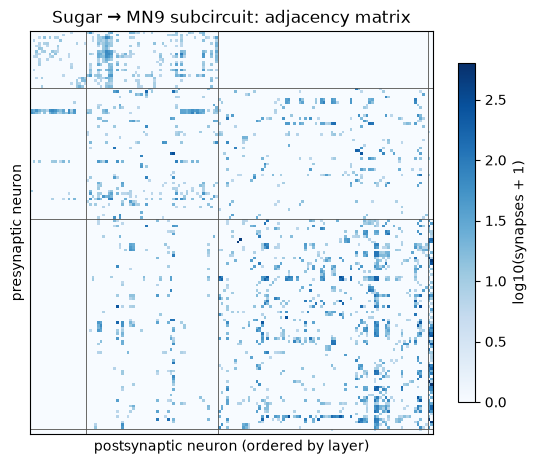

In [41]:
layer_sizes = members.groupby("layer").size()
bounds = np.cumsum(layer_sizes.values)[:-1] - 0.5

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(np.log10(A.values + 1), cmap="Blues", interpolation="nearest")
for b in bounds:
    ax.axhline(b, color="#52514e", lw=0.6)
    ax.axvline(b, color="#52514e", lw=0.6)
ax.set_xlabel("postsynaptic neuron (ordered by layer)")
ax.set_ylabel("presynaptic neuron")
ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=ax, label="log10(synapses + 1)", shrink=0.8)
ax.set_title("Sugar → MN9 subcircuit: adjacency matrix");

> **Look at the matrix:** The lines separate the GRNs (top/left block), 1-hop, 2-hop, … neurons. Where are most of the connections? Do you see connections going "backwards" (from later to earlier layers)? What would they mean?

### 4.2 Giving connections a sign
A synapse count tells us *how strong* a connection is, but not *what it does*. Following Shiu et al., we use each neuron's predicted neurotransmitter:

| transmitter | effect in the fly brain | sign |
|---|---|---|
| acetylcholine | mostly excitatory | **+1** |
| GABA | inhibitory | **−1** |
| glutamate | mostly inhibitory in the central brain (via glutamate-gated chloride channels) | **−1** |
| dopamine, serotonin, octopamine | neuromodulators: effects depend on receptors | **+1** (a simplification) |

This rule makes several assumptions: one transmitter per neuron (*Dale's law*), the same effect at every target, and predictions that are correct. Keep them in mind!

First, which transmitters are in our circuit?

In [42]:
members.top_nt.value_counts()

top_nt
acetylcholine    94
gaba             39
glutamate        13
dopamine          3
serotonin         1
Name: count, dtype: int64

Next, apply those signs to our adjacency matrix:

In [43]:
SIGN = {"acetylcholine": +1, "gaba": -1, "glutamate": -1}   # everything else: +1

# +1 or -1 for every member; SIGN.get(nt, +1) returns +1 for transmitters that aren't in SIGN
sign = pd.Series({n: SIGN.get(info.top_nt.get(n), +1) for n in order})

# Each row (= presynaptic neuron) is multiplied by that neuron's sign
W = A.mul(sign, axis=0)
# Fractions of neurons, connections (non-zero entries) and synapses that are inhibitory
print(f"inhibitory neurons:     {(sign < 0).mean():.0%}")
print(f"inhibitory connections: {(W < 0).values.sum() / (W != 0).values.sum():.0%}")
print(f"inhibitory synapses:    {-W[W < 0].sum().sum() / A.values.sum():.0%}")

inhibitory neurons:     35%
inhibitory connections: 39%
inhibitory synapses:    42%


And plot

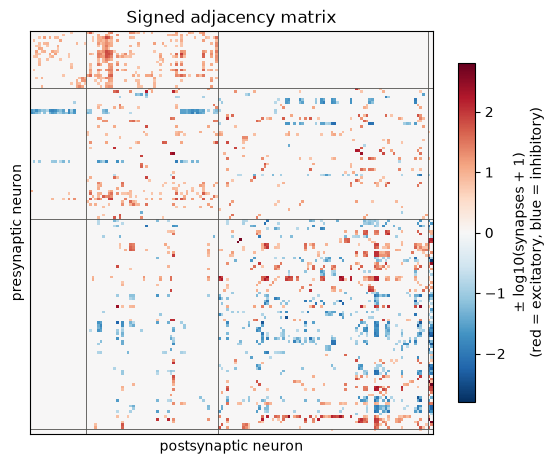

In [44]:
signed_log = np.sign(W.values) * np.log10(np.abs(W.values) + 1)
vmax = np.abs(signed_log).max()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(signed_log, cmap="RdBu_r", vmin=-vmax, vmax=vmax, interpolation="nearest")
for b in bounds:
    ax.axhline(b, color="#52514e", lw=0.6)
    ax.axvline(b, color="#52514e", lw=0.6)
ax.set_xticks([]); ax.set_yticks([])
ax.set_xlabel("postsynaptic neuron"); ax.set_ylabel("presynaptic neuron")
fig.colorbar(im, ax=ax, label="± log10(synapses + 1)\n(red = excitatory, blue = inhibitory)", shrink=0.8)
ax.set_title("Signed adjacency matrix");

Notice that each **row** has a single color: a neuron is either excitatory or inhibitory to *all* its targets. That's Dale's law, built into our sign rule.

---
## 5. Graph statistics

Now let's describe the circuit with a few numbers. First, we hand the matrix `A` to `networkx`, a package for graphs, which will compute graph statistics for us:

In [ ]:
# networkx graph of the circuit: nodes = neurons, edges = connections (weight = synapses)
sub = nx.from_pandas_adjacency(A, create_using=nx.DiGraph)
print(sub)

DiGraph with 150 nodes and 2079 edges


### 5.1 Size and density
**Density** is the fraction of all possible connections that actually exist: `E / (N × (N − 1))` for a directed graph.

In [47]:
N, E = sub.number_of_nodes(), sub.number_of_edges()
print(f"neurons: {N}, connections: {E}")
print(f"density: {nx.density(sub):.3f}")
print(f"average partners per neuron (in + out): {2 * E / N:.1f}")

neurons: 150, connections: 2079
density: 0.093
average partners per neuron (in + out): 27.7


For comparison, the whole FlyWire brain has a density of roughly **0.0001**: each neuron connects to about 20 of the ~139,000 others (at ≥ 5 synapses). Our subcircuit is hundreds of times denser. By construction it contains neurons that talk to each other.

### 5.2 Who are the hubs?
The **degree** of a neuron is its number of partners, split into in-degree (inputs) and out-degree (outputs). The **strength** is the same with synapse counts instead.

In [48]:
# Degree = number of partners; the 'synapses' columns count synapses instead of partners
stats = pd.DataFrame({
    "name": [nice_name(n) for n in order],
    "transmitter": [info.top_nt.get(n) for n in order],
    "in_degree": [sub.in_degree(n) for n in order],
    "out_degree": [sub.out_degree(n) for n in order],
    "in_synapses": [sub.in_degree(n, weight="weight") for n in order],
    "out_synapses": [sub.out_degree(n, weight="weight") for n in order],
}, index=order)
stats["total_synapses"] = stats.in_synapses + stats.out_synapses
stats.sort_values("total_synapses", ascending=False).head(10)

,name,transmitter,in_degree,out_degree,in_synapses,out_synapses,total_synapses
720575940618238523,CB0701,acetylcholine,57,3,4458,16,4474
720575940660219265,CB0701,acetylcholine,52,0,4220,0,4220
720575940615671106,DNge059,acetylcholine,51,11,2926,312,3238
720575940607272649,roundup (CB0553),acetylcholine,35,26,1411,1749,3160
720575940623211725,roundup (CB0553),acetylcholine,41,22,1980,1080,3060
720575940619877396,DNge059,acetylcholine,48,7,2632,271,2903
720575940616848214,puddle (CB0923),acetylcholine,27,37,1066,1746,2812
720575940617678566,CB0587,acetylcholine,14,34,259,2144,2403
720575940617787963,CB0587,acetylcholine,16,35,183,1982,2165
720575940612443890,CB0903,gaba,12,24,1035,976,2011


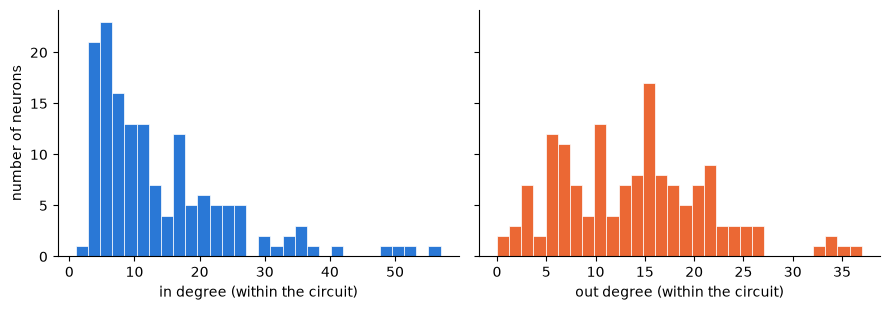

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, col, color in zip(axes, ["in_degree", "out_degree"], ["#2a78d6", "#eb6834"]):
    ax.hist(stats[col], bins=30, color=color, edgecolor="white", linewidth=0.5)
    ax.set_xlabel(col.replace("_", " ") + " (within the circuit)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("number of neurons")
plt.tight_layout()

### 5.3 Reciprocity
How often do two neurons connect in **both** directions (`a → b` *and* `b → a`)? In a random network, the chance of a returning connection is just the density. Let's compare:

In [50]:
recip = nx.reciprocity(sub)   # fraction of connections that are reciprocated
print(f"reciprocity: {recip:.2f}")
print(f"expected if random (= density): {nx.density(sub):.2f}")
print(f"→ {recip / nx.density(sub):.1f}× more reciprocal connections than chance")

reciprocity: 0.23
expected if random (= density): 0.09
→ 2.5× more reciprocal connections than chance


Over-representation of reciprocal connections is a common feature of brain networks, and it points to recurrent loops, not a simple feed-forward chain.

### 5.4 Paths and their signs
The **sign of a path** is the product of the signs along it. Two inhibitory steps make a net *excitatory* path (**disinhibition**: inhibiting an inhibitor). Let's enumerate all paths of up to `MAX_HOPS` from the sugar GRNs to MN9:

In [51]:
def all_paths(graph, sources, targets, max_hops):
    # Every path of at most max_hops connections from any source to any target
    return [p for s in sources if s in graph for t in targets if t in graph
            for p in nx.all_simple_paths(graph, s, t, cutoff=max_hops)]

def path_sign(path):
    # product of the signs of all presynaptic neurons along the path
    return int(np.prod([SIGN.get(info.top_nt.get(n), +1) for n in path[:-1]]))

def path_strength(graph, path):
    # the weakest link (fewest synapses) along the path
    return min(graph[a][b]["weight"] for a, b in zip(path[:-1], path[1:]))

paths = all_paths(sub, sugar, mn9, MAX_HOPS)
signs = np.array([path_sign(p) for p in paths])
print(f"{len(paths)} paths: {np.mean(signs > 0):.0%} net excitatory, {np.mean(signs < 0):.0%} net inhibitory")

2072 paths: 63% net excitatory, 37% net inhibitory


In [52]:
# Group paths that pass through the same cell types (e.g. left and right copies of a neuron)
routes = {}
for p in paths:
    route = tuple(nice_name(n) for n in p)
    # The current count and best strength of this route (zeros if we haven't seen it yet)
    count, best, sgn = routes.get(route, (0, 0, path_sign(p)))
    routes[route] = (count + 1, max(best, path_strength(sub, p)), sgn)

# The 10 strongest routes (strength = weakest link of the best path)
# Sort the routes by their best strength, strongest first
for route, (count, best, sgn) in sorted(routes.items(), key=lambda kv: -kv[1][1])[:10]:
    print(f"{'+' if sgn > 0 else '−'}  min {best:>3} syn, {count:>2} path(s):  ", " → ".join(route))

+  min  50 syn, 38 path(s):   LB3c → G2N_1 (CB0616) → DNge080 → CB0701
+  min  42 syn, 16 path(s):   LB3d → G2N_1 (CB0616) → DNge080 → CB0701
+  min  33 syn, 11 path(s):   LB3c → G2N_1 (CB0616) → roundup (CB0553) → CB0701
+  min  33 syn,  5 path(s):   LB3d → G2N_1 (CB0616) → roundup (CB0553) → CB0701
−  min  27 syn, 30 path(s):   LB3c → CB0118 → CB0709 → CB0701
+  min  27 syn, 45 path(s):   LB3c → CB0118 → CB0856 → CB0701
+  min  27 syn, 60 path(s):   LB3c → CB0118 → CB0862 → CB0701
+  min  27 syn, 60 path(s):   LB3c → CB0118 → DNge055 → CB0701
−  min  27 syn, 14 path(s):   LB3d → CB0118 → CB0709 → CB0701
+  min  27 syn, 21 path(s):   LB3d → CB0118 → CB0856 → CB0701


Each line is a *route*: a sequence of cell types, with `+` for net excitatory and `−` for net inhibitory. Several individual paths (e.g. through the left and right copy of a neuron type) can share a route.

### 5.5 Excitation and inhibition onto MN9

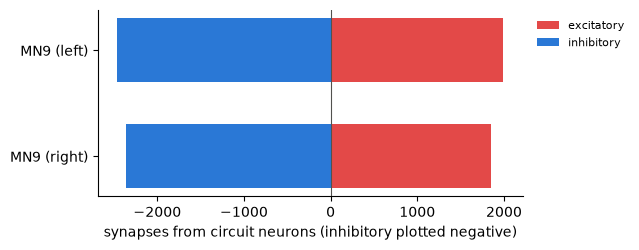

In [53]:
# The signed inputs to each MN9 (one column per MN9)
mn9_in = W.loc[:, [m for m in mn9 if m in W.columns]]
# Sum the excitatory (positive) and inhibitory (negative) entries separately
exc, inh = mn9_in.clip(lower=0).sum(), -mn9_in.clip(upper=0).sum()

fig, ax = plt.subplots(figsize=(6.5, 2.6))
labels = [f"MN9 ({info.side.get(m)})" for m in mn9_in.columns]
ax.barh(labels, exc, color="#e34948", height=0.6, label="excitatory")
ax.barh(labels, -inh, color="#2a78d6", height=0.6, label="inhibitory")
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_xlabel("synapses from circuit neurons (inhibitory plotted negative)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

> **Discuss (2 min):** Within this circuit, does MN9 receive more excitatory or inhibitory synapses? And yet Shiu et al.'s model predicts that sugar *activates* MN9. How can both be true? What can't the wiring diagram alone tell us?

<details><summary>Show discussion points</summary>

* What matters is which inputs are **active**. Sugar may drive mostly the excitatory routes, while many inhibitory neurons in the circuit are driven by *other* inputs (e.g. bitter taste or satiety signals) that are silent here.
* Disinhibitory paths (− × − = +) turn inhibition into excitation.
* Timing, thresholds and nonlinear dynamics matter. That's exactly what a simulation (Day 2!) adds to the static wiring diagram.
</details>

### 5.6 Drawing the circuit
Finally, a picture: nodes arranged in columns by their distance from the sugar GRNs. To keep it readable we only draw the stronger connections.

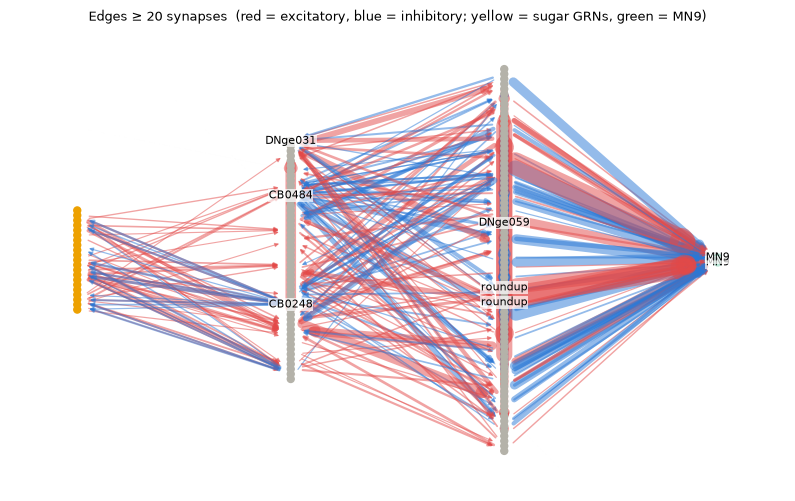

In [54]:
def draw_circuit(graph, layer, sources, targets, min_weight=20, ax=None):
    ax = ax or plt.subplots(figsize=(10, 6))[1]
    # columns = layer (hops from the inputs); the output neurons always get the last column
    last = max(layer[n] for n in graph.nodes if n not in targets) + 1
    for n in graph.nodes:
        graph.nodes[n]["layer"] = last if n in targets else layer[n]
    pos = nx.multipartite_layout(graph, subset_key="layer")
    strong = [(a, b) for a, b, w in graph.edges(data="weight") if w >= min_weight]
    colors = ["#e34948" if SIGN.get(info.top_nt.get(a), +1) > 0 else "#2a78d6" for a, b in strong]
    widths = [0.3 + graph[a][b]["weight"] / 40 for a, b in strong]
    nx.draw_networkx_edges(graph, pos, edgelist=strong, edge_color=colors, width=widths,
                           alpha=0.5, arrowsize=6, ax=ax)
    node_color = ["#eda100" if n in sources else "#1baf7a" if n in targets else "#b4b2a9"
                  for n in graph.nodes]
    nx.draw_networkx_nodes(graph, pos, node_size=25, node_color=node_color, ax=ax)
    # label the 3 strongest-connected interneurons in each column, plus the outputs
    labels = {}
    for col in range(1, last):
        inter = [n for n in graph.nodes if graph.nodes[n]["layer"] == col and n not in sources]
        for n in sorted(inter, key=lambda n: -graph.degree(n, weight="weight"))[:3]:
            labels[n] = nice_name(n).split(" (")[0]
    labels.update({t: "MN9" for t in targets if t in graph})
    nx.draw_networkx_labels(graph, pos, labels=labels, font_size=8, ax=ax,
                            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=0.5))
    ax.set_title(f"Edges ≥ {min_weight} synapses  (red = excitatory, blue = inhibitory; "
                 "yellow = sugar GRNs, green = MN9)", fontsize=9)
    ax.axis("off")
    return ax

draw_circuit(sub, layer, sugar, mn9);

---
## 6. Small exercises

These exercises reuse the functions and variables from Sections 2–5. The code that reshapes tables is given; the gaps (`___`) are the decisions that a connectomics analysis has to make: which neurons to compare, and what to assume about them. Each step follows the same pattern:

* **Predict:** before you run the cell, write down what you expect.
* **Check:** after running it, compare with the expected result (below the cell).
* **Think:** discuss what the result means. Solutions and discussion points are hidden under each step.

### Exercise 1 **Sugar vs bitter.**

Sugar makes a fly extend its proboscis and start feeding; bitter taste makes it stop. Is that difference visible in the wiring? Build the circuit from the **bitter** GRNs to MN9 in the same way as the sugar circuit, and compare the two.

**Step 1: choose the bitter GRNs and build both circuits.** The taste of each GRN is in the `cell_sub_class` annotation (the sugar GRNs, for example, are `"sugar"` or `"sugar/low_salt"`). For a fair comparison, take the bitter GRNs from the same side of the brain as our sugar GRNs (Section 1.1). Then give each set of GRNs to `get_circuit` (Section 3.3) as the sources.

**Predict:** will the bitter circuit be larger or smaller than the sugar circuit?

In [ ]:
# The bitter GRNs: fill in their cell_sub_class and their side
bitter = ann.root_id[(ann.cell_sub_class == ___) & (ann.side == ___)].tolist()
print(len(bitter), "bitter GRNs")

A_sugar, layer_sugar = get_circuit(___, mn9, max_hops=3, threshold=THRESHOLD)
A_bitter, layer_bitter = get_circuit(___, mn9, max_hops=3, threshold=THRESHOLD)
print(len(A_sugar), "neurons in the sugar circuit,", len(A_bitter), "in the bitter circuit")

**Check:** 150 neurons in the sugar circuit and 108 in the bitter circuit.

**Think:** the bitter circuit is smaller. Does that mean bitter has less influence on MN9? What else would you need to know?

<details><summary>Show solution</summary>

```python
bitter = ann.root_id[(ann.cell_sub_class == "bitter") & (ann.side == "left")].tolist()
A_sugar, layer_sugar = get_circuit(sugar, mn9, max_hops=3, threshold=THRESHOLD)
A_bitter, layer_bitter = get_circuit(bitter, mn9, max_hops=3, threshold=THRESHOLD)
```

Not necessarily: a few strong connections can matter more than many weak ones. We'd also need the synapse numbers along the way, and the signs of the connections (Step 2).
</details>

**Step 2: net-inhibitory paths.** The cell below lists all paths of up to 3 hops from the GRNs to MN9 in each circuit (`all_paths`, Section 5.4) and gets their signs (`path_sign`). Remember that a path is net inhibitory if it passes through an odd number of inhibitory neurons.

**Predict:** sugar drives proboscis extension and bitter suppresses it. Which circuit should have the larger fraction of net-inhibitory paths onto MN9?

In [ ]:
paths_by = {}   # the paths of each circuit (we'll reuse them in Exercise 3)
for name, A_, sources in [("sugar", A_sugar, sugar), ("bitter", A_bitter, bitter)]:
    G_ = nx.from_pandas_adjacency(A_, create_using=nx.DiGraph)
    paths_by[name] = all_paths(G_, sources, mn9, max_hops=3)
    signs_ = np.array([path_sign(p) for p in paths_by[name]])
    print(f"{name}: {len(paths_by[name])} paths, {np.mean(signs_ < 0):.0%} net inhibitory")

**Check:** sugar: 2,072 paths, 37% net inhibitory. Bitter: 869 paths, 59% net inhibitory.

**Think:**
* Does the difference match what the fly does with each taste?
* A path through *two* inhibitory neurons counts as net excitatory. What does that assume about the neurons along the path?
* Every path counts the same here. What does that leave out? (Look back at `path_strength` in Section 5.4.)

<details><summary>Show discussion points</summary>

* Broadly, yes: most sugar paths are net excitatory and most bitter paths are net inhibitory. But both circuits contain both kinds of path, so the path count alone doesn't decide what MN9 does.
* Multiplying the signs assumes that inhibiting an inhibitory neuron excites its targets (*disinhibition*). That only works if the inhibitory neuron is active to begin with.
* Path counts ignore synapse numbers: a path through a 5-synapse connection counts as much as one through 100 synapses. They also ignore which neurons are actually active and when. A network model (Day 2) takes all of this into account.
</details>

**Step 3: shared and private neurons.** Some neurons are in both circuits, others in only one. The cell below sorts the members into `shared`, `sugar_only` and `bitter_only` neurons, and compares the predicted transmitters of the three groups. Notice that MN9 is left out of `shared`: why?

**Predict:** which group do you expect to have the largest fraction of inhibitory (GABA or glutamate) neurons?

In [ ]:
shared = np.setdiff1d(np.intersect1d(A_sugar.index, A_bitter.index), mn9)   # in both circuits, except MN9
sugar_only = np.setdiff1d(A_sugar.index, A_bitter.index)                     # in the sugar circuit only
bitter_only = np.setdiff1d(A_bitter.index, A_sugar.index)                    # in the bitter circuit only
groups = {"shared": shared, "sugar-only": sugar_only, "bitter-only": bitter_only}

for group, ids in groups.items():
    # isin(...).mean() is the fraction of the group predicted to use GABA or glutamate
    print(f"{group}: {len(ids)} neurons, {info.top_nt.reindex(ids).isin(['gaba', 'glutamate']).mean():.0%} inhibitory")

# The predicted transmitters of each group
# reindex(ids) picks the rows of the given IDs; one column of transmitter counts per group
pd.DataFrame({group: info.top_nt.reindex(ids).value_counts() for group, ids in groups.items()}).fillna(0).astype(int)

**Check:** 55 shared neurons (51% inhibitory), 93 sugar-only (26% inhibitory) and 51 bitter-only (41% inhibitory).

**Think:**
* Which transmitters stand out in the bitter-only group?
* What could the shared neurons be doing?

<details><summary>Show discussion points</summary>

* MN9 is the target of both circuits by definition, so finding it in both tells us nothing.
* The bitter-only group stands out for glutamate (12) and serotonin (7). The "serotonergic" neurons turn out to be bitter GRNs themselves; keep that in mind for Exercise 3!
* The shared neurons are where the two tastes converge on their way to MN9. One hypothesis: they are premotor neurons that both tastes act on, with sugar recruiting more excitatory and bitter more inhibitory routes to them.
</details>

### Exercise 2 **Same side or opposite side?**

All 21 sugar GRNs enter the brain on the *left* (in FlyWire's convention), but there is an MN9 on each side: one on the same side as the GRNs (*ipsilateral*) and one on the opposite side (*contralateral*). Does the sugar signal reach both equally well? This exercise uses the sugar circuit from Sections 2–5 (`members` and `paths`).

**Step 1: where are the circuit members?** The cell below looks up the side of each member and counts the members per layer and side.

**Predict:** is the circuit mostly on the left, or split evenly between the sides? In which layer do the first right-side neurons appear?

In [ ]:
# Look up the side of each member in the annotations
members["side"] = members.root_id.map(info.side)
pd.crosstab(members.layer, members.side, margins=True)

**Check:** 99 members on the left, 49 on the right and 2 in the middle. 15 of the 49 layer-1 neurons are already on the right side.

**Think:** the `side` annotation is the side of the neuron's cell body. How can a neuron on the right receive synapses directly from GRNs that enter the brain on the left?

<details><summary>Show discussion points</summary>

Synapses don't have to be on the same side as the cell body: either the GRN axons cross the midline, or the right-side neuron sends its dendrites across to the left. The synapse locations (Part 2) would tell us which.
</details>

**Step 2: how directly does sugar reach each MN9?** For each MN9, the cell below takes the paths from Section 5.4 (`paths`) that end on it, and reports the shortest path (in hops), the number of paths and the fraction that is net excitatory.

**Predict:** which MN9 will be reached by the shortest path? Which by more paths?

In [ ]:
for m in mn9:
    to_m = [p for p in paths if p[-1] == m]          # the paths that end on this MN9
    signs_m = np.array([path_sign(p) for p in to_m])
    print(f"MN9 ({info.side[m]}): shortest {min(len(p) - 1 for p in to_m)} hops, "
          f"{len(to_m)} paths, {np.mean(signs_m > 0):.0%} net excitatory")

**Check:** left MN9: shortest path 2 hops, 1,207 paths, 58% net excitatory. Right MN9: 3 hops, 865 paths, 70% net excitatory.

**Think:** the contralateral MN9 is one hop further away, but a larger fraction of its paths is net excitatory. Which MN9 do you think the sugar GRNs drive more strongly? What would you need to know to be sure?

<details><summary>Show discussion points</summary>

From the wiring alone, we can't tell: the ipsilateral MN9 gets more and shorter paths, the contralateral one a larger fraction of excitatory ones. We'd need the synapse numbers along the paths and how strongly each neuron responds, i.e. a model, or a recording from both MN9s while stimulating the GRNs on one side.
</details>

**Step 3: who crosses the midline?** Select the members that receive input *directly* from the (left) sugar GRNs but have their cell body on the right side: fill in their layer and side. Do you recognize any names from earlier?

In [ ]:
right_layer1 = members[(members.layer == ___) & (members.side == ___)]
right_layer1["name"].tolist()

**Check:** 15 neurons.

**Think:** why might it be useful for sugar on one side of the mouthparts to drive the MN9s on *both* sides?

<details><summary>Show solution + discussion points</summary>

```python
right_layer1 = members[(members.layer == 1) & (members.side == "right")]
```

* The 15 right-side layer-1 neurons include named neurons such as G2N-1, Rattle and Clavicle (right-side copies of neurons that the sugar GRNs also drive on the left), and even a right-side sugar GRN (LB3c). The sugar signal crosses the midline right after the first synapse.
* Proboscis extension is a single movement of the whole proboscis, so a sugar signal from one side may need to drive the muscles on both sides.
</details>

### Exercise 3 **How far can we trust the signs?**

Every path sign in Exercise 1 depends on two things: our sign rule (Section 4.2) and the neurotransmitter predictions. Let's test both. This exercise uses `paths_by` from Exercise 1.

**Step 1: change the sign rule.** Glutamate is inhibitory at many central synapses in the fly (through glutamate-gated chloride channels), but excitatory at others (for example at the neuromuscular junction). Fill in a second rule in which glutamate is excitatory. The cell then recomputes the fraction of net-excitatory paths in both circuits with both rules (`path_sign_rule` works like `path_sign`, but takes the rule as an argument).

**Predict:** which circuit will change more? Hint: look back at the transmitter table in Exercise 1, Step 3.

In [ ]:
def path_sign_rule(path, rule):
    # like path_sign (Section 5.4), but with the sign rule as an argument
    return int(np.prod([rule.get(info.top_nt.get(n), +1) for n in path[:-1]]))

GLU_EXCITATORY = {"acetylcholine": +1, "gaba": -1, "glutamate": ___}

for name, paths_ in paths_by.items():
    original = np.mean([path_sign_rule(p, SIGN) > 0 for p in paths_])
    glu_exc = np.mean([path_sign_rule(p, GLU_EXCITATORY) > 0 for p in paths_])
    print(f"{name}: {original:.0%} net excitatory -> {glu_exc:.0%} with glutamate excitatory")

**Check:** sugar: 63% net excitatory with the original rule, 57% with glutamate excitatory. Bitter: 41% → 59%.

**Think:** how much does the sugar/bitter contrast from Exercise 1 rest on this one assumption? Whether a glutamatergic synapse excites or inhibits depends on the receptors of the *postsynaptic* neuron. How could you find out?

<details><summary>Show solution + discussion points</summary>

```python
GLU_EXCITATORY = {"acetylcholine": +1, "gaba": -1, "glutamate": +1}
```

* The bitter circuit flips from mostly net inhibitory to mostly net excitatory, because many of its paths run through glutamatergic neurons. So the sugar/bitter contrast from Exercise 1 depends on a single assumption about one transmitter!
* Gene expression data (e.g. single-cell transcriptomics or receptor reporter lines) can tell us which glutamate receptors a neuron makes; recordings or optogenetics can test the sign of a connection directly.
</details>

**Step 2: how confident are the predictions?** Each neuron's prediction comes with a confidence between 0 and 1 (`top_nt_conf`, Part 1). For each circuit, the cell below lists the members predicted with a confidence below `MIN_CONF`. It then keeps only the paths in which every neuron is predicted with at least that confidence (except MN9 at the end, which doesn't affect the sign), and recomputes the fraction of net-inhibitory paths.

**Predict:** will the net-inhibitory fractions from Exercise 1 survive this filter? Which circuit is more likely to change?

In [ ]:
MIN_CONF = 0.5   # try other values, too

for name, A_ in [("sugar", A_sugar), ("bitter", A_bitter)]:
    # The prediction confidence of every member of this circuit
    conf = info.top_nt_conf.reindex(A_.index)
    low = conf.index[conf < MIN_CONF]
    print(f"{name}: {len(low)} of {len(A_)} members below {MIN_CONF}:", info.top_nt.reindex(low).value_counts().to_dict())
    print("   ", sorted({nice_name(n) for n in low}))

    paths_ = paths_by[name]
    # keep a path if every neuron (except the last) has a confident prediction
    confident = [p for p in paths_ if all(info.top_nt_conf.get(n, 0) >= MIN_CONF for n in p[:-1])]
    before = np.mean([path_sign(p) < 0 for p in paths_])
    after = np.mean([path_sign(p) < 0 for p in confident])
    print(f"    {len(confident)} of {len(paths_)} paths left; net inhibitory {before:.0%} -> {after:.0%}")

**Check** (with `MIN_CONF = 0.5`): sugar: 20 of 150 members below 0.5. 1,412 of 2,072 paths are left, and the net-inhibitory fraction barely changes (37% → 36%). Bitter: 22 of 108 members below 0.5. Only 35 of 869 paths are left, and the fraction drops from 59% to 40%.

**Think:** so is the bitter result unreliable? Look closely at *which* neurons have low confidence before you decide.

**Step 3: use what we know.** Which kind of neuron makes up most of the low-confidence list in Step 2? What do we know about the transmitter of that kind of neuron from other experiments? Fill in `trusted`: the neurons whose sign we know without the predictor. The cell then repeats the filtering from Step 2, but always keeps the trusted neurons. Hint: in the loop, `sources` holds the input neurons of the current circuit.

**Predict:** once we trust these neurons, will the bitter result hold up?

In [ ]:
for name, sources in [("sugar", sugar), ("bitter", bitter)]:
    trusted = set(___)   # the neurons whose sign we know without the predictor
    paths_ = paths_by[name]
    # keep a path if every neuron (except the last) is trusted or has a confident prediction
    confident = [p for p in paths_ if all(n in trusted or info.top_nt_conf.get(n, 0) >= MIN_CONF for n in p[:-1])]
    before = np.mean([path_sign(p) < 0 for p in paths_])
    after = np.mean([path_sign(p) < 0 for p in confident])
    print(f"{name}: {len(confident)} of {len(paths_)} paths left; net inhibitory {before:.0%} -> {after:.0%}")

**Check:** sugar: 1,855 of 2,072 paths left, 37% → 38% net inhibitory. Bitter: 792 of 869 paths left, 59% → 62% net inhibitory.

<details><summary>Show solution + discussion points</summary>

```python
trusted = set(sources)
```

* Most of the low-confidence neurons are the GRNs themselves (8 of the 20 in the sugar circuit, and 16 of the 22 in the bitter circuit; 7 bitter GRNs are even predicted to be serotonergic). Insect sensory neurons such as GRNs are thought to be cholinergic, so we don't need the predictor to tell us their sign.
* Both results hold up once we use what we know about the GRNs. The naive filter in Step 2 made the bitter result look fragile only because it threw away the bitter circuit's own sensory neurons.
* Predictions are hypotheses: combine them with prior knowledge where you can, and check how much your conclusions depend on them.
</details>

---
## Wrap-up

* A **subcircuit** needs a definition. Ours is "short paths from input to output above a synapse threshold," and the choices (`THRESHOLD`, `MAX_HOPS`, which input neurons) change the answer.
* The **adjacency matrix** stores the circuit. **Signs** from neurotransmitter predictions turn it into a hypothesis about *function*, with every assumption that comes with it.
* **Graph statistics** (density, degree, reciprocity, path signs) describe the structure. Predicting *activity* needs a model.

### Bridge to Day 2
Save the signed matrix and the neuron table. Together they're everything a simple network model needs:

In [ ]:
W.to_csv("sugar_circuit_signed_adjacency.csv")
# Add each member's sign as a column, then save the table
members.assign(sign=members.root_id.map(sign)).to_csv("sugar_circuit_neurons.csv", index=False)
print("saved:", W.shape[0], "neurons")

### References
* Shiu et al. (2024) *A Drosophila computational brain model reveals sensorimotor processing.* Nature 634, 210–219. Code: [github.com/philshiu/Drosophila_brain_model](https://github.com/philshiu/Drosophila_brain_model)
* Dorkenwald et al. (2024) *Neuronal wiring diagram of an adult brain.* Nature
* Schlegel et al. (2024) *Whole-brain annotation and multi-connectome cell typing of Drosophila.* Nature
* Eckstein et al. (2024) *Neurotransmitter classification from electron microscopy images at synaptic sites in Drosophila melanogaster.* Cell
* Tastekin et al. (2026) Cell, for the current taste-modality annotations of the GRNs (see the [FlyWire annotations changelog](https://github.com/flyconnectome/flywire_annotations))